# Pipeline CPU n°2 — PyTorch → TorchScript / torch.compile → CPU

**TP Déploiement IA — analyse comparative de pipelines de déploiement (CPU / GPU)**

| Couche | Dans ce notebook |
|---|---|
| Haut niveau | PyTorch — ResNet-18 pré-entraîné ImageNet |
| Format du modèle | graphe TorchScript (trace) et graphe FX PyTorch 2 (TorchDynamo) |
| Middle level | compilation PyTorch : freeze / optimize_for_inference (TorchScript), AOTAutograd + Inductor (torch.compile) |
| Bas niveau | kernels C++/OpenMP générés par Inductor + appels oneDNN (mkldnn) et MKL |
| Matériel | CPU Google Colab |

**Environnement Colab : CPU** (*Exécution > Modifier le type d'exécution*), puis *Exécution > Tout exécuter*.

**Variantes mesurées dans ce notebook**
- `pytorch_eager` — PyTorch eager FP32 (référence, même CPU)
- `torchscript` — TorchScript : trace + freeze + optimize_for_inference (approche PyTorch 1.x)
- `torch_compile` — **pipeline étudié** : `torch.compile` (TorchDynamo → AOTAutograd → Inductor), FP32

## 0. Installation

PyTorch est préinstallé sur Colab : aucune installation n'est nécessaire (Inductor utilise le compilateur C++ du système).

In [1]:
!pip list 2>/dev/null | grep -E "^(torch|torchvision) "
!g++ --version | head -1

torch                     2.15.0
torchvision               0.29.2


Apple clang version 21.0.0 (clang-2100.1.1.101)


In [2]:
# Identifiant du pipeline (seule cellule de configuration propre à ce notebook)
PIPELINE_ID = "cpu2_torch"
PIPELINE_LABEL = "CPU 2 · PyTorch → torch.compile (Inductor)"
PLATFORM = "CPU"
PIPELINE_LAYERS = {
    "haut_niveau": "PyTorch",
    "format": "TorchScript / graphe FX (TorchDynamo)",
    "middle_level": "torch.compile (AOTAutograd + Inductor)",
    "bas_niveau": "kernels C++ générés + oneDNN",
    "materiel": "CPU Google Colab",
}

## 1. Protocole expérimental commun

Les cellules « COMMUNE » ci-dessous sont **strictement identiques dans les 4 notebooks** : mêmes données, même prétraitement, même modèle, même méthode de mesure.

| Élément | Choix |
|---|---|
| Données | 50 images du jeu de test CIFAR-10 : les 5 premières de chaque classe (sous-ensemble équilibré et déterministe ; indices et empreintes SHA-256 enregistrés) |
| Prétraitement | 32×32 → 224×224 (bilinéaire), puis normalisation ImageNet (moyenne 0,485 / 0,456 / 0,406 ; écart-type 0,229 / 0,224 / 0,225) |
| Modèle | ResNet-18 torchvision, poids `IMAGENET1K_V1`, sans réentraînement |
| Top-1 sur 10 classes | les 1000 classes ImageNet sont regroupées en 10 super-classes CIFAR-10 (somme des probabilités softmax), prédiction = argmax des 10 scores |
| Performances | batch de 10 (5 batchs), 10 batchs de chauffe, puis **10 exécutions** chronométrées du passage complet ; chaque batch est chronométré avec synchronisation du GPU ; les données sont déjà en mémoire du device |
| Statistiques | moyenne, écart-type, minimum, maximum et coefficient de variation (CV = écart-type / moyenne) |
| Énergie | GPU : NVML (énergie de la carte) ; CPU : Intel RAPL si la VM l'expose (rarement sur Colab) ; fenêtres d'au moins 5 s |
| Référence | chaque notebook mesure aussi **PyTorch eager FP32 sur le même matériel** : accélérations et écarts de prédiction sont calculés dans les mêmes conditions |

In [3]:
# ============ CELLULE COMMUNE 1/6 : imports, paramètres expérimentaux, environnement ============
# (identique dans les 4 notebooks : ne modifier qu'ici, et de la même façon partout)
import os, sys, gc, re, glob, json, time, copy, hashlib, platform, datetime, threading, warnings
from collections import Counter
import numpy as np
import pandas as pd
import torch
import torchvision
from torchvision import transforms
from torchvision.models import resnet18, ResNet18_Weights

SEED = 0
IMAGES_PER_CLASS = 5        # 5 images x 10 classes = 50 images (sous-ensemble équilibré et déterministe)
BATCH_SIZE = 10             # même taille de batch pour les 4 pipelines : 50 images = 5 batchs
N_WARMUP = 10               # batchs de chauffe, non chronométrés
N_RUNS = 10                 # exécutions chronométrées du passage complet sur les 50 images (>= 3 exigées)
ENERGY_WINDOW_S = 5.0       # durée minimale d'une fenêtre de mesure énergétique (résolution des capteurs)
N_ENERGY_RUNS = 3           # répétitions de la mesure énergétique
IDLE_WINDOW_S = 2.0         # mesure de la puissance au repos (avant chaque série)
IMG_SIZE = 224
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)
RESULTS_DIR, FIGURES_DIR = "results", "figures"
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

torch.manual_seed(SEED)
np.random.seed(SEED)

DEVICE = "cuda" if PLATFORM == "GPU" else "cpu"
if DEVICE == "cuda":
    assert torch.cuda.is_available(), "Aucun GPU détecté : Exécution > Modifier le type d'exécution > GPU (T4)."
    torch.backends.cudnn.benchmark = True   # formes fixes : cuDNN choisit son meilleur algorithme une fois pour toutes
else:
    torch.set_num_threads(os.cpu_count())
    if torch.cuda.is_available():
        print("⚠️ Un GPU est visible : pour des conditions comparables, exécuter ce notebook sur un environnement CPU.")
N_THREADS = torch.get_num_threads()


def get_env_info():
    """Décrit la machine et les versions logicielles (enregistré avec les résultats)."""
    info = {
        "date_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds"),
        "python": platform.python_version(), "os": platform.platform(),
        "cpu_count": os.cpu_count(), "torch_threads": N_THREADS,
        "torch": torch.__version__, "torchvision": torchvision.__version__,
    }
    try:
        lines = open("/proc/cpuinfo").read().splitlines()
        info["cpu_model"] = next(l.split(":", 1)[1].strip() for l in lines if l.startswith("model name"))
        flags = next(l.split(":", 1)[1].split() for l in lines if l.startswith("flags"))
        info["cpu_isa"] = [f for f in ("avx2", "avx512f", "avx512_vnni", "avx512_bf16", "amx_bf16") if f in flags]
    except Exception:
        info["cpu_model"] = platform.processor()
    try:
        info["ram_gb"] = round(int(open("/proc/meminfo").readline().split()[1]) / 1024**2, 1)
    except Exception:
        pass
    if torch.cuda.is_available():
        p = torch.cuda.get_device_properties(0)
        info.update(gpu=p.name, gpu_mem_gb=round(p.total_memory / 1024**3, 1),
                    gpu_compute_capability=f"{p.major}.{p.minor}",
                    cuda=torch.version.cuda, cudnn=torch.backends.cudnn.version())
    for mod in ("onnx", "onnxruntime", "openvino", "tensorrt"):
        try:
            info[mod] = __import__(mod).__version__
        except Exception:
            pass
    return info


for k, v in get_env_info().items():
    print(f"{k:>24} : {v}")

                date_utc : 2026-11-20T17:26:04+00:00
                  python : 3.12.15
                      os : macOS-26.7.1-arm64-arm-64bit
               cpu_count : 12
           torch_threads : 12
                   torch : 2.15.0
             torchvision : 0.29.2
               cpu_model : arm
                    onnx : 1.23.2
             onnxruntime : 1.32.0
                openvino : 2026.4.1-22982-e213a147257-releases/2026/4


In [4]:
# ============ CELLULE COMMUNE 2/6 : données (50 images CIFAR-10) et prétraitement ============
CIFAR10_CLASSES = ("airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck")

testset = torchvision.datasets.CIFAR10(root="./data", train=False, download=True)
targets = np.asarray(testset.targets)
# Sous-ensemble déterministe : les 5 premières images de chaque classe dans l'ordre du jeu de test
SUBSET_INDICES = sorted(int(i) for c in range(10) for i in np.flatnonzero(targets == c)[:IMAGES_PER_CLASS])
images_pil = [testset[i][0] for i in SUBSET_INDICES]          # images PIL 32x32
LABELS = targets[SUBSET_INDICES]
N_IMAGES = len(SUBSET_INDICES)
assert N_IMAGES == 50 and N_IMAGES % BATCH_SIZE == 0

# Prétraitement aligné sur le pré-entraînement ImageNet de ResNet-18 :
# redimensionnement 32x32 -> 224x224 (bilinéaire) puis normalisation avec la moyenne / l'écart-type ImageNet.
# (Pas de Resize(256)+CenterCrop(224) : sur une image 32x32 agrandie, le recadrage couperait l'objet.)
preprocess = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE), interpolation=transforms.InterpolationMode.BILINEAR, antialias=True),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
X_ALL = torch.stack([preprocess(im) for im in images_pil]).contiguous()     # (50, 3, 224, 224) float32
CPU_BATCHES = [b.contiguous() for b in torch.split(X_ALL, BATCH_SIZE)]      # 5 batchs de 10, pré-chargés en mémoire

# Empreintes : permettent de vérifier que les 4 notebooks ont traité EXACTEMENT les mêmes entrées
RAW_SHA = hashlib.sha256(np.stack([np.asarray(im) for im in images_pil]).tobytes()).hexdigest()[:16]
INPUT_SHA = hashlib.sha256(X_ALL.numpy().tobytes()).hexdigest()[:16]
print(f"{N_IMAGES} images | répartition : {np.bincount(LABELS, minlength=10).tolist()} | tenseur {tuple(X_ALL.shape)}")
print(f"empreinte images brutes : {RAW_SHA} | empreinte tenseur prétraité : {INPUT_SHA}")

50 images | répartition : [5, 5, 5, 5, 5, 5, 5, 5, 5, 5] | tenseur (50, 3, 224, 224)
empreinte images brutes : ac22f720f545b224 | empreinte tenseur prétraité : b581e1365a579ac5


In [5]:
# ============ CELLULE COMMUNE 3/6 : modèle ResNet-18 ImageNet et évaluation sur 10 classes ============
WEIGHTS = ResNet18_Weights.IMAGENET1K_V1
model = resnet18(weights=WEIGHTS).eval()
IMAGENET_CATEGORIES = WEIGHTS.meta["categories"]
WEIGHTS_SHA = hashlib.sha256(b"".join(t.detach().cpu().numpy().tobytes()
                                      for t in model.state_dict().values())).hexdigest()[:16]
print(f"ResNet-18 ({WEIGHTS.name}) : {sum(p.numel() for p in model.parameters())/1e6:.1f} M paramètres | empreinte poids : {WEIGHTS_SHA}")

# Le modèle pré-entraîné produit 1000 logits ImageNet. Pour mesurer une précision Top-1 sur les
# 10 classes CIFAR-10 SANS réentraîner (le modèle reste identique dans les 4 pipelines), on regroupe
# les classes ImageNet correspondant à chaque classe CIFAR-10 : score(c) = somme des probabilités
# softmax des classes ImageNet associées à c ; prédiction = argmax des 10 scores.
# Plages (a, b) = familles d'indices ImageNet contiguës ; chaînes = noms de classes ImageNet.
CIFAR_TO_IMAGENET = {
    "airplane":   ["airliner", "warplane", "wing"],
    "automobile": ["sports car", "convertible", "cab", "beach wagon", "jeep", "limousine",
                   "minivan", "Model T", "racer"],
    "bird":       [(7, 24), (80, 100), (127, 146)],
    "cat":        [(281, 285)],                              # tabby ... Egyptian cat (chats domestiques)
    "deer":       ["hartebeest", "impala", "gazelle"],       # ImageNet-1k n'a pas de classe « cerf »
    "dog":        [(151, 268)],                              # Chihuahua ... Mexican hairless
    "frog":       ["bullfrog", "tree frog", "tailed frog"],
    "horse":      ["sorrel", "horse cart"],
    "ship":       ["container ship", "liner", "pirate", "schooner", "submarine", "yawl", "catamaran",
                   "trimaran", "fireboat", "lifeboat", "speedboat", "aircraft carrier", "wreck",
                   "gondola", "canoe"],
    "truck":      ["trailer truck", "fire engine", "garbage truck", "moving van", "tow truck"],
}
_name_to_idx = {n: i for i, n in enumerate(IMAGENET_CATEGORIES)}
CIFAR_GROUPS = []
for c in CIFAR10_CLASSES:
    idx = []
    for spec in CIFAR_TO_IMAGENET[c]:
        idx += list(range(spec[0], spec[1] + 1)) if isinstance(spec, tuple) else [_name_to_idx[spec]]
    CIFAR_GROUPS.append(np.array(sorted(set(idx))))
print("classes ImageNet regroupées par classe CIFAR-10 :", {c: len(g) for c, g in zip(CIFAR10_CLASSES, CIFAR_GROUPS)})


def softmax(z):
    z = z.astype(np.float64) - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)


def cifar_predictions(logits):
    p = softmax(logits)
    return np.stack([p[:, g].sum(axis=1) for g in CIFAR_GROUPS], axis=1).argmax(axis=1)


def evaluate_logits(logits):
    pred = cifar_predictions(logits)
    correct = pred == LABELS
    return {"top1_accuracy": float(correct.mean()), "n_correct": int(correct.sum()),
            "per_class_accuracy": {c: float(correct[LABELS == k].mean()) for k, c in enumerate(CIFAR10_CLASSES)},
            "cifar_pred": pred.tolist(), "imagenet_top1": logits.argmax(axis=1).tolist()}


def compare_logits(logits, ref):
    """Écart d'une variante à la référence PyTorch eager FP32 (même notebook, même device)."""
    d = np.abs(logits.astype(np.float64) - ref.astype(np.float64))
    return {"max_abs_diff": float(d.max()), "mean_abs_diff": float(d.mean()),
            "imagenet_top1_agreement": float((logits.argmax(1) == ref.argmax(1)).mean()),
            "imagenet_top5_overlap": float(np.mean([len(set(a) & set(b)) / 5 for a, b in
                                                    zip(np.argsort(-logits, 1)[:, :5], np.argsort(-ref, 1)[:, :5])])),
            "cifar_pred_agreement": float((cifar_predictions(logits) == cifar_predictions(ref)).mean())}

ResNet-18 (IMAGENET1K_V1) : 11.7 M paramètres | empreinte poids : 94c3ff0d5591a630
classes ImageNet regroupées par classe CIFAR-10 : {'airplane': 3, 'automobile': 9, 'bird': 59, 'cat': 5, 'deer': 3, 'dog': 118, 'frog': 3, 'horse': 2, 'ship': 15, 'truck': 5}


In [6]:
# ============ CELLULE COMMUNE 4/6 : mesure des performances et de l'énergie ============
def sync():
    """Les appels GPU sont asynchrones : on attend la fin réelle du calcul avant de lire l'horloge."""
    if DEVICE == "cuda":
        torch.cuda.synchronize()


def benchmark(infer_fn, batches, n_warmup=N_WARMUP, n_runs=N_RUNS):
    """Chauffe, puis n_runs passages complets sur les 50 images ; chaque batch est chronométré
    (time.perf_counter + synchronisation). Données déjà en mémoire du device : seul le calcul
    d'inférence est mesuré. Le ramasse-miettes Python est suspendu pendant chaque passage."""
    for i in range(n_warmup):
        infer_fn(batches[i % len(batches)])
    sync()
    runs = []
    for _ in range(n_runs):
        gc.collect()
        gc.disable()
        try:
            lat_ms = []
            for b in batches:
                t0 = time.perf_counter()
                infer_fn(b)
                sync()
                lat_ms.append((time.perf_counter() - t0) * 1e3)
        finally:
            gc.enable()
        total_s = sum(lat_ms) / 1e3
        runs.append({"total_s": total_s,
                     "throughput_img_s": N_IMAGES / total_s,
                     "latency_per_image_ms": total_s * 1e3 / N_IMAGES,
                     "latency_batch_mean_ms": float(np.mean(lat_ms)),
                     "latency_batch_ms": lat_ms})
    return runs


def describe(values):
    """Moyenne, écart-type (non biaisé), min, max et coefficient de variation."""
    v = np.asarray(values, dtype=float)
    std = float(v.std(ddof=1)) if v.size > 1 else 0.0
    mean = float(v.mean())
    return {"mean": mean, "std": std, "min": float(v.min()), "max": float(v.max()),
            "cv_pct": 100 * std / mean if mean else None, "n": int(v.size)}


def summarize_runs(runs):
    out = {k: describe([r[k] for r in runs])
           for k in ("throughput_img_s", "latency_per_image_ms", "latency_batch_mean_ms", "total_s")}
    all_batches = np.concatenate([r["latency_batch_ms"] for r in runs])
    out["latency_batch_p50_ms"] = float(np.percentile(all_batches, 50))
    out["latency_batch_p95_ms"] = float(np.percentile(all_batches, 95))
    return out


class EnergyMeter:
    """Énergie consommée pendant l'exécution d'une fonction.
    GPU : NVML (compteur d'énergie de la carte si disponible, sinon puissance échantillonnée x durée).
    CPU : Intel RAPL (/sys/class/powercap), rarement exposé dans les VM Colab -> mesure alors indisponible.
    Périmètre : carte GPU seule (NVML) ou package CPU entier (RAPL), jamais la machine complète."""

    def __init__(self, device, sample_period_s=0.02):
        self.device, self.period, self.source, self.rapl = device, sample_period_s, None, []
        if device == "cuda":
            try:
                import pynvml
                pynvml.nvmlInit()
                self.nvml, self.handle = pynvml, pynvml.nvmlDeviceGetHandleByIndex(0)
                try:
                    pynvml.nvmlDeviceGetTotalEnergyConsumption(self.handle)
                    self.source = "NVML (compteur d'énergie GPU)"
                except pynvml.NVMLError:
                    self.source = "NVML (puissance échantillonnée)"
            except Exception as e:
                print("NVML indisponible :", e)
        else:
            for d in sorted(glob.glob("/sys/class/powercap/intel-rapl:[0-9]")):   # domaines « package »
                try:
                    int(open(f"{d}/energy_uj").read())
                    self.rapl.append((f"{d}/energy_uj", int(open(f"{d}/max_energy_range_uj").read())))
                except (OSError, ValueError):
                    pass
            if self.rapl:
                self.source = "Intel RAPL (package CPU)"
        print("Mesure énergétique :", self.source or "non disponible sur cette machine (aucun capteur accessible)")

    @property
    def available(self):
        return self.source is not None

    def _power_w(self):
        return self.nvml.nvmlDeviceGetPowerUsage(self.handle) / 1000.0          # mW -> W

    def _counter(self):
        if self.device == "cuda":
            return self.nvml.nvmlDeviceGetTotalEnergyConsumption(self.handle) / 1000.0   # mJ -> J
        return [int(open(p).read()) for p, _ in self.rapl]                          # µJ par domaine

    def _delta_j(self, c0, c1):
        if self.device == "cuda":
            return c1 - c0
        return sum((b - a) if b >= a else (b + rng - a)                             # débordement du compteur
                   for a, b, (_, rng) in zip(c0, c1, self.rapl)) / 1e6

    def measure(self, fn, min_duration_s):
        samples, stop = [], threading.Event()

        def sampler():
            while not stop.is_set():
                samples.append(self._power_w())
                time.sleep(self.period)

        use_counter = self.device == "cpu" or "compteur" in self.source
        thread = threading.Thread(target=sampler, daemon=True) if self.device == "cuda" else None
        if thread:
            thread.start()
        c0 = self._counter() if use_counter else None
        t0, n_calls = time.perf_counter(), 0
        while True:
            fn()
            n_calls += 1
            if time.perf_counter() - t0 >= min_duration_s:
                break
        duration = time.perf_counter() - t0
        c1 = self._counter() if use_counter else None
        if thread:
            stop.set()
            thread.join()
        energy = self._delta_j(c0, c1) if use_counter else float(np.mean(samples)) * duration
        return {"energy_j": float(energy), "duration_s": duration, "n_calls": n_calls,
                "avg_power_w": energy / duration, "max_power_w": max(samples) if samples else None}


METER = EnergyMeter(DEVICE)


def measure_energy(infer_fn, batches):
    """Fenêtres d'au moins ENERGY_WINDOW_S secondes (passages complets répétés), car 50 images ne
    durent que quelques millisecondes sur GPU : trop court pour la résolution des capteurs."""
    if not METER.available:
        return None

    def full_pass():
        for b in batches:
            infer_fn(b)
        sync()

    idle_w = METER.measure(lambda: time.sleep(0.05), IDLE_WINDOW_S)["avg_power_w"]
    runs = []
    for _ in range(N_ENERGY_RUNS):
        m = METER.measure(full_pass, ENERGY_WINDOW_S)
        n_img = m["n_calls"] * N_IMAGES
        m.update(n_images=n_img, idle_power_w=idle_w,
                 energy_per_image_j=m["energy_j"] / n_img,
                 net_energy_per_image_j=max(m["avg_power_w"] - idle_w, 0.0) * m["duration_s"] / n_img)
        runs.append(m)
    return {"source": METER.source, "idle_power_w": idle_w, "runs": runs,
            "stats": {k: describe([r[k] for r in runs])
                      for k in ("avg_power_w", "energy_per_image_j", "net_energy_per_image_j")}}

Mesure énergétique : non disponible sur cette machine (aucun capteur accessible)


In [7]:
# ============ CELLULE COMMUNE 5/6 : évaluation d'une variante et enregistrement ============
RESULTS = {"pipeline_id": PIPELINE_ID, "pipeline_label": PIPELINE_LABEL, "platform": PLATFORM,
           "layers": PIPELINE_LAYERS, "principal_variant": None, "variants": {}, "graph_info": {}}
LOGITS = {}
REF_NAME = None


def to_numpy(y):
    """Sortie d'une variante -> tableau NumPy float32 (copie : certains runtimes réutilisent leur buffer)."""
    if isinstance(y, torch.Tensor):
        sync()
        return y.detach().float().cpu().numpy().copy()
    return np.array(y, dtype=np.float32, copy=True)


def timed_call(fn, *args):
    """Durée (s) d'un appel unique, synchronisé (ex. : premier appel qui déclenche une compilation)."""
    t0 = time.perf_counter()
    out = fn(*args)
    sync()
    return time.perf_counter() - t0, out


def evaluate_variant(name, label, infer_fn, batches, precision="FP32", role="variante",
                     prep_time_s=None, notes=""):
    """Évalue une variante : 1) qualité des prédictions, 2) latence / débit sur N_RUNS exécutions,
    3) énergie (si un capteur est disponible).
    role : 'reference' (PyTorch eager FP32, même device), 'principal' (pipeline étudié) ou 'variante'."""
    global REF_NAME
    print(f"\n=== {label} ===")
    logits = np.concatenate([to_numpy(infer_fn(b)) for b in batches])
    LOGITS[name] = logits
    if role == "reference":
        REF_NAME = name
    quality = evaluate_logits(logits)
    vs_ref = compare_logits(logits, LOGITS[REF_NAME]) if REF_NAME and name != REF_NAME else None
    runs = benchmark(infer_fn, batches)
    perf = summarize_runs(runs)
    energy = measure_energy(infer_fn, batches)
    RESULTS["variants"][name] = {"label": label, "precision": precision, "role": role,
                                 "prep_time_s": prep_time_s, "notes": notes, "runs": runs, "perf": perf,
                                 "quality": quality, "vs_reference": vs_ref, "energy": energy}
    if role == "principal":
        RESULTS["principal_variant"] = name
    t, l = perf["throughput_img_s"], perf["latency_per_image_ms"]
    print(f"débit   : {t['mean']:.1f} ± {t['std']:.1f} img/s  (min {t['min']:.1f}, max {t['max']:.1f}, CV {t['cv_pct']:.1f} %)")
    print(f"latence : {l['mean']:.2f} ± {l['std']:.2f} ms/image | batch p50 {perf['latency_batch_p50_ms']:.1f} ms, p95 {perf['latency_batch_p95_ms']:.1f} ms")
    print(f"Top-1 CIFAR-10 : {quality['top1_accuracy']:.0%} ({quality['n_correct']}/{N_IMAGES})", end="")
    if vs_ref:
        print(f" | accord top-1 ImageNet vs réf. : {vs_ref['imagenet_top1_agreement']:.0%}"
              f" | écart max logits : {vs_ref['max_abs_diff']:.2e}", end="")
    print()
    if energy:
        e = energy["stats"]
        print(f"énergie : {1e3 * e['energy_per_image_j']['mean']:.2f} ± {1e3 * e['energy_per_image_j']['std']:.2f} mJ/image"
              f" | puissance moyenne {e['avg_power_w']['mean']:.1f} W (repos {energy['idle_power_w']:.1f} W)")
    if prep_time_s is not None:
        print(f"préparation (export / compilation / construction) : {prep_time_s:.1f} s")

## 2. Référence : PyTorch eager sur CPU

In [8]:
model_cpu = model.to("cpu").eval()


@torch.no_grad()
def infer_eager(x):
    return model_cpu(x)


evaluate_variant("pytorch_eager", "PyTorch eager (référence)", infer_eager, CPU_BATCHES, role="reference")


=== PyTorch eager (référence) ===


débit   : 129.8 ± 7.2 img/s  (min 120.8, max 143.5, CV 5.5 %)
latence : 7.73 ± 0.42 ms/image | batch p50 77.0 ms, p95 86.0 ms
Top-1 CIFAR-10 : 54% (27/50)


## 3. Variante PyTorch 1.x : TorchScript

`torch.jit.trace` enregistre les opérations exécutées sur un exemple et produit un graphe TorchScript ; `freeze` transforme les poids en constantes (ce qui permet de **plier les BatchNorm dans les convolutions**) ; `optimize_for_inference` applique des passes propres au CPU (couches oneDNN/MKLDNN).

*À observer* dans le tableau : disparition des `batch_norm`, apparition d'opérations `mkldnn`, réduction du nombre de nœuds.

In [9]:
TS_MODEL, TS_EXAMPLE = model_cpu, CPU_BATCHES[0]
def ts_stats(graph):
    kinds = Counter(n.kind() for n in graph.nodes())
    return {"noeuds": sum(kinds.values()),
            "batch_norm": kinds.get("aten::batch_norm", 0),
            "convolutions": kinds.get("aten::_convolution", 0) + kinds.get("aten::conv2d", 0)
                            + kinds.get("prim::mkldnn_convolution", 0),
            "ops spécialisées (mkldnn / cudnn)": sum(v for k, v in kinds.items()
                                                     if "mkldnn" in k.lower() or "cudnn" in k.lower())}


TS_OK = False
try:
    with torch.no_grad(), warnings.catch_warnings():
        warnings.simplefilter("ignore")   # torch.jit est déprécié (au profit de torch.compile / torch.export) mais fonctionne
        t0 = time.perf_counter()
        ts_traced = torch.jit.trace(TS_MODEL, TS_EXAMPLE)          # Python -> graphe TorchScript (traçage)
        stages = {"tracé": ts_stats(ts_traced.inlined_graph)}
        ts_frozen = torch.jit.freeze(ts_traced)                   # poids figés en constantes, Conv+BN pliées
        stages["figé (freeze)"] = ts_stats(ts_frozen.graph)
        ts_model = torch.jit.optimize_for_inference(ts_frozen)    # passes spécifiques à l'inférence sur ce device
        stages["optimisé (optimize_for_inference)"] = ts_stats(ts_model.graph)
        for _ in range(3):                                        # l'exécuteur JIT spécialise le graphe aux 1ers appels
            ts_model(TS_EXAMPLE)
        sync()
        ts_prep_s = time.perf_counter() - t0
    display(pd.DataFrame(stages).T)
    RESULTS["graph_info"]["torchscript"] = stages
    TS_OK = True
except Exception as e:
    print("TorchScript indisponible dans cette version de PyTorch :", repr(e)[:300])

if TS_OK:
    @torch.no_grad()
    def infer_torchscript(x):
        return ts_model(x)

    evaluate_variant("torchscript", "TorchScript (trace + freeze)", infer_torchscript, CPU_BATCHES,
                     role="variante", prep_time_s=ts_prep_s)

,noeuds,batch_norm,convolutions,ops spécialisées (mkldnn / cudnn)
tracé,372,20,20,0
figé (freeze),99,0,20,0
optimisé (optimize_for_inference),102,0,20,0



=== TorchScript (trace + freeze) ===


débit   : 133.2 ± 7.1 img/s  (min 119.4, max 142.0, CV 5.3 %)
latence : 7.52 ± 0.42 ms/image | batch p50 74.5 ms, p95 86.3 ms
Top-1 CIFAR-10 : 54% (27/50) | accord top-1 ImageNet vs réf. : 100% | écart max logits : 3.24e-05
préparation (export / compilation / construction) : 0.8 s


## 4. Middle level PyTorch 2 : `torch.compile`

1. **TorchDynamo** capture le code Python en graphe FX (`explain` indique le nombre de graphes et de *graph breaks* : idéalement 1 graphe, 0 rupture).
2. **AOTAutograd** décompose le graphe en opérations élémentaires (ATen) ;
3. **Inductor** optimise et **génère du code** : kernels C++/OpenMP fusionnés (`cpp_fused_*`) pour les opérations élémentaires, et appels à oneDNN/MKL pour les convolutions et la couche linéaire.

Avec `freezing = True`, Inductor traite les poids comme des constantes (équivalent du `freeze` TorchScript). Le premier appel déclenche la compilation : sa durée est enregistrée comme coût de préparation. Inductor met en cache les compilations : une 2ᵉ exécution du notebook dans la même session compile plus vite.

In [10]:
import torch._inductor.config as inductor_config
from torch._inductor.utils import run_and_get_code

inductor_config.freezing = True   # poids traités comme constantes (inférence) : pliage Conv+BN, pré-formatage des poids
COMPILE_MODE = "default"          # autres modes : "max-autotune" (recherche de kernels, compilation bien plus longue)


def inductor_code_stats(code):
    """Résume le code généré par Inductor : kernels fusionnés générés vs appels à des bibliothèques."""
    kernels = sorted(set(re.findall(r"\b((?:cpp|triton)_\w*fused\w*)", code)))
    calls = Counter(c for c in re.findall(r"((?:torch\.ops\.\w+|extern_kernels)\.\w+)(?:\.\w+)?\(", code)
                    if not c.startswith("torch.ops.inductor"))
    return {"generated_fused_kernels": len(kernels), "kernel_examples": kernels[:6],
            "library_calls": dict(calls.most_common(8))}


def compile_and_capture(net, example):
    """1er appel d'un modèle torch.compile = compilation (Dynamo -> AOTAutograd -> Inductor) ; on récupère le code généré."""
    compiled = torch.compile(net, backend="inductor", mode=COMPILE_MODE)
    t0 = time.perf_counter()
    with torch.no_grad():
        _, codes = run_and_get_code(compiled, example)
    sync()
    return compiled, time.perf_counter() - t0, inductor_code_stats("\n".join(codes))

MODEL_FOR_EXPLAIN, EXAMPLE_FOR_EXPLAIN = model_cpu, CPU_BATCHES[0]
try:
    exp = torch._dynamo.explain(MODEL_FOR_EXPLAIN)(EXAMPLE_FOR_EXPLAIN)
    print(f"TorchDynamo : {exp.graph_count} graphe(s) capturé(s), {exp.graph_break_count} rupture(s) de graphe, "
          f"{exp.op_count} opérations")
    RESULTS["graph_info"]["dynamo"] = {"graphs": exp.graph_count, "graph_breaks": exp.graph_break_count,
                                       "ops": exp.op_count}
except Exception as e:
    print("torch._dynamo.explain indisponible :", repr(e)[:200])
torch._dynamo.reset()

TorchDynamo : 1 graphe(s) capturé(s), 0 rupture(s) de graphe, 69 opérations


In [11]:
compiled_cpu, compile_s, inductor_info = compile_and_capture(model_cpu, CPU_BATCHES[0])
RESULTS["graph_info"]["inductor"] = inductor_info | {"compile_time_s": round(compile_s, 1), "mode": COMPILE_MODE}
print(f"compilation (1er appel) : {compile_s:.1f} s")
print(json.dumps(inductor_info, indent=1))


@torch.no_grad()
def infer_compiled(x):
    return compiled_cpu(x)


evaluate_variant("torch_compile", "torch.compile (Inductor, FP32)", infer_compiled, CPU_BATCHES,
                 role="principal", prep_time_s=compile_s, notes=f"mode={COMPILE_MODE}, freezing=True")

compilation (1er appel) : 12.5 s
{
 "generated_fused_kernels": 11,
 "kernel_examples": [
  "cpp_fused_add_mean_relu_10",
  "cpp_fused_add_relu_3",
  "cpp_fused_add_relu_5",
  "cpp_fused_add_relu_7",
  "cpp_fused_add_relu_9",
  "cpp_fused_convolution_0"
 ],
 "library_calls": {
  "extern_kernels.convolution": 20,
  "extern_kernels.addmm": 1
 }
}

=== torch.compile (Inductor, FP32) ===


débit   : 133.0 ± 1.2 img/s  (min 130.9, max 135.2, CV 0.9 %)
latence : 7.52 ± 0.07 ms/image | batch p50 74.2 ms, p95 80.0 ms
Top-1 CIFAR-10 : 54% (27/50) | accord top-1 ImageNet vs réf. : 100% | écart max logits : 2.96e-05
préparation (export / compilation / construction) : 12.5 s


## Résultats du notebook et sauvegarde

Le tableau et les deux figures ci-dessous résument les variantes mesurées. La cellule enregistre `results/<pipeline>.json` (mesures brutes, statistiques, environnement) et `results/<pipeline>_logits.npz` (sorties du modèle, pour comparer les prédictions entre pipelines), puis télécharge une archive à décompresser à la racine du dépôt.

In [12]:
# ============ CELLULE COMMUNE 6/6 : tableau récapitulatif, graphiques et sauvegarde ============
import matplotlib.pyplot as plt

PIPELINE_COLORS = {"cpu1_openvino": "#2a78d6", "cpu2_torch": "#eb6834",
                   "gpu1_tensorrt": "#1baf7a", "gpu2_torch": "#eda100"}
MUTED, INK, INK2, GRID, AXIS, SURFACE = "#898781", "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
                     "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
                     "xtick.color": INK2, "ytick.color": INK2, "axes.spines.top": False,
                     "axes.spines.right": False, "grid.color": GRID, "grid.linewidth": 0.8,
                     "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
                     "legend.frameon": False, "figure.dpi": 110})


def results_table():
    rows = []
    for v in RESULTS["variants"].values():
        p, q, e, r = v["perf"], v["quality"], v["energy"], v["vs_reference"]
        t, l = p["throughput_img_s"], p["latency_per_image_ms"]
        rows.append({
            "variante": v["label"], "rôle": v["role"], "précision": v["precision"],
            "débit moy. (img/s)": round(t["mean"], 1), "écart-type": round(t["std"], 1),
            "min": round(t["min"], 1), "max": round(t["max"], 1), "CV (%)": round(t["cv_pct"], 2),
            "latence (ms/img)": f"{l['mean']:.2f} ± {l['std']:.2f}",
            "batch p50 / p95 (ms)": f"{p['latency_batch_p50_ms']:.1f} / {p['latency_batch_p95_ms']:.1f}",
            "temps 50 img (s)": f"{p['total_s']['mean']:.3f} ± {p['total_s']['std']:.3f}",
            "Top-1 CIFAR-10": f"{q['top1_accuracy']:.0%}",
            "accord top-1 vs réf.": f"{r['imagenet_top1_agreement']:.0%}" if r else "—",
            "écart max logits": f"{r['max_abs_diff']:.1e}" if r else "—",
            "énergie (mJ/img)": f"{1e3 * e['stats']['energy_per_image_j']['mean']:.2f} ± {1e3 * e['stats']['energy_per_image_j']['std']:.2f}" if e else "n/d",
            "puissance (W)": f"{e['stats']['avg_power_w']['mean']:.1f}" if e else "n/d",
            "préparation (s)": f"{v['prep_time_s']:.1f}" if v["prep_time_s"] is not None else "—",
        })
    return pd.DataFrame(rows)


def plot_local_results():
    """Figure 1 : débit moyen ± écart-type (points = exécutions). Figure 2 : stabilité run par run."""
    names = list(RESULTS["variants"])
    color = PIPELINE_COLORS.get(PIPELINE_ID, "#2a78d6")
    fig, ax = plt.subplots(figsize=(8, 0.55 * len(names) + 1.4))
    for i, n in enumerate(names):
        v = RESULTS["variants"][n]
        t = v["perf"]["throughput_img_s"]
        c = color if v["role"] == "principal" else MUTED
        ax.barh(i, t["mean"], height=0.55, color=c, edgecolor=SURFACE, linewidth=2)
        ax.errorbar(t["mean"], i, xerr=t["std"], color=INK2, capsize=3, lw=1)
        pts = [r["throughput_img_s"] for r in v["runs"]]
        ax.scatter(pts, i + np.linspace(-0.12, 0.12, len(pts)), s=10, color=INK, alpha=0.55, zorder=3)
        ax.text(max(t["max"], t["mean"] + t["std"]) * 1.02, i, f"{t['mean']:.1f} ± {t['std']:.1f} img/s", va="center", fontsize=9, color=INK)
    ax.set_yticks(range(len(names)), [RESULTS["variants"][n]["label"] for n in names])
    ax.invert_yaxis()
    ax.set_xlabel(f"débit (images/s) — barre = moyenne, trait = ± 1 écart-type, points = {N_RUNS} exécutions (batch {BATCH_SIZE})")
    from matplotlib.patches import Patch
    ax.legend(handles=[Patch(color=color, label="pipeline étudié"), Patch(color=MUTED, label="référence et variantes")],
              loc="lower right", fontsize=8)
    ax.set_xlim(0, max(RESULTS["variants"][n]["perf"]["throughput_img_s"]["max"] for n in names) * 1.35)
    ax.grid(axis="x")
    ax.set_title(f"{PIPELINE_LABEL} — débit de traitement", loc="left")
    fig.tight_layout()
    fig.savefig(f"{FIGURES_DIR}/{PIPELINE_ID}_debit.png", bbox_inches="tight")
    plt.show()

    fig, axes = plt.subplots(1, len(names), figsize=(3.2 * len(names), 2.8), squeeze=False)
    series = {n: np.array([r["throughput_img_s"] for r in RESULTS["variants"][n]["runs"]]) for n in names}
    lim = max(0.2, 1.15 * max(np.abs(y / y.mean() - 1).max() for y in series.values()))   # échelle relative commune
    for ax, n in zip(axes[0], names):
        v = RESULTS["variants"][n]
        y = series[n]
        x = np.arange(1, len(y) + 1)
        c = color if v["role"] == "principal" else MUTED
        ax.fill_between(x, y.mean() - y.std(ddof=1), y.mean() + y.std(ddof=1), color=c, alpha=0.18, lw=0)
        ax.axhline(y.mean(), color=c, lw=1)
        ax.plot(x, y, marker="o", ms=4, lw=2, color=c)
        ax.set_title(v["label"], fontsize=9)
        ax.set_xlabel("exécution n°")
        ax.grid(axis="y")
        ax.set_ylim(y.mean() * (1 - lim), y.mean() * (1 + lim))   # même échelle relative : variabilités comparables
    axes[0][0].set_ylabel("débit (img/s)")
    fig.suptitle(f"Stabilité run par run (ligne = moyenne, bande = ± 1 écart-type, échelle ± {lim:.0%} autour de la moyenne)",
                 fontsize=10, color=INK)
    fig.tight_layout()
    fig.savefig(f"{FIGURES_DIR}/{PIPELINE_ID}_stabilite.png", bbox_inches="tight")
    plt.show()


def save_results():
    RESULTS.update(env=get_env_info(), input_sha=INPUT_SHA, raw_images_sha=RAW_SHA, weights_sha=WEIGHTS_SHA,
                   subset_indices=SUBSET_INDICES, labels=LABELS.tolist(), reference_variant=REF_NAME,
                   config={"n_images": N_IMAGES, "batch_size": BATCH_SIZE, "n_warmup": N_WARMUP,
                           "n_runs": N_RUNS, "energy_window_s": ENERGY_WINDOW_S,
                           "n_energy_runs": N_ENERGY_RUNS, "img_size": IMG_SIZE, "seed": SEED,
                           "mean": IMAGENET_MEAN, "std": IMAGENET_STD, "threads": N_THREADS})
    with open(f"{RESULTS_DIR}/{PIPELINE_ID}.json", "w", encoding="utf-8") as f:
        json.dump(RESULTS, f, indent=2, ensure_ascii=False)
    np.savez_compressed(f"{RESULTS_DIR}/{PIPELINE_ID}_logits.npz", **LOGITS)
    print("Résultats enregistrés :", f"{RESULTS_DIR}/{PIPELINE_ID}.json", "et", f"{RESULTS_DIR}/{PIPELINE_ID}_logits.npz")

,variante,rôle,précision,débit moy. (img/s),écart-type,min,max,CV (%),latence (ms/img),batch p50 / p95 (ms),temps 50 img (s),Top-1 CIFAR-10,accord top-1 vs réf.,écart max logits,énergie (mJ/img),puissance (W),préparation (s)
0,PyTorch eager (référence),reference,FP32,129.8,7.2,120.8,143.5,5.54,7.73 ± 0.42,77.0 / 86.0,0.386 ± 0.021,54%,—,—,n/d,n/d,—
1,TorchScript (trace + freeze),variante,FP32,133.2,7.1,119.4,142.0,5.32,7.52 ± 0.42,74.5 / 86.3,0.376 ± 0.021,54%,100%,3.2e-05,n/d,n/d,0.8
2,"torch.compile (Inductor, FP32)",principal,FP32,133.0,1.2,130.9,135.2,0.90,7.52 ± 0.07,74.2 / 80.0,0.376 ± 0.003,54%,100%,3.0e-05,n/d,n/d,12.5


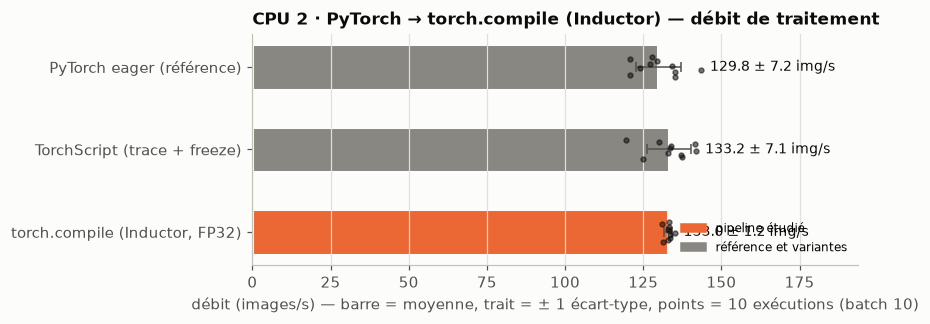

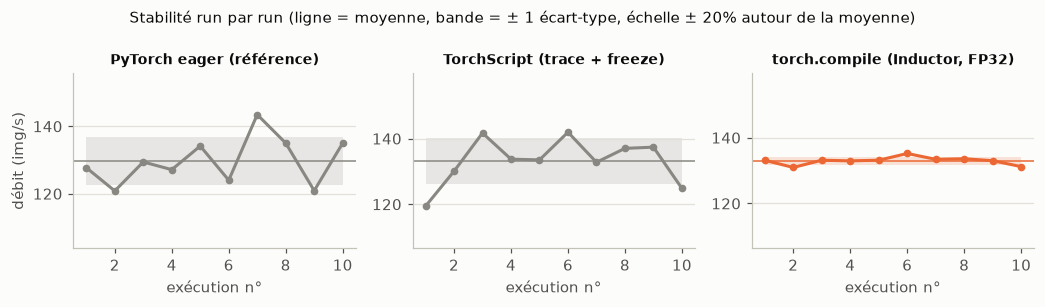

Résultats enregistrés : results/cpu2_torch.json et results/cpu2_torch_logits.npz
Hors Colab : archive créée -> cpu2_torch_sorties.zip


In [13]:
results_df = results_table()
display(results_df)
plot_local_results()
save_results()

# Archive à télécharger (Colab) : à décompresser à la racine du dépôt (dossiers results/ et figures/)
import shutil, zipfile
archive = f"{PIPELINE_ID}_sorties.zip"
with zipfile.ZipFile(archive, "w") as z:
    for folder in (RESULTS_DIR, FIGURES_DIR):
        for path in glob.glob(f"{folder}/{PIPELINE_ID}*"):
            z.write(path)
try:
    from google.colab import files
    files.download(archive)
except ImportError:
    print("Hors Colab : archive créée ->", archive)

## Analyse (à compléter à partir de vos résultats)

- **Gain du pipeline** : accélération de `torch.compile` par rapport à eager, et de TorchScript par rapport à eager. Lequel des deux compilateurs PyTorch apporte le plus, et l'écart est-il significatif au regard des écarts-types ?
- **Ce que fait le compilateur** : nombre de graphes / ruptures (Dynamo), nombre de kernels fusionnés générés, part des calculs déléguée à oneDNN/MKL. Pourquoi les convolutions restent-elles confiées à une bibliothèque ?
- **Coût de préparation** : durée de compilation vs gain par image — à partir de combien d'images la compilation est-elle rentabilisée ?
- **Qualité** : Top-1 et accord des prédictions avec la référence ; ordre de grandeur de l'écart des logits.
- **Comparaison avec le pipeline CPU n°1** (OpenVINO) : à faire dans le notebook 05.